<a href="https://colab.research.google.com/github/ElizavetaDovzhuk/-/blob/master/%D0%BF%D1%80%D0%B5%D0%BA%D0%BC%D0%B5%D0%B5%D0%B5%D1%85.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

b	Угол быстрого проворота, °	ω2 max	ω2 min	max|d²φ2/dφ1²|
0.10	168.60			1.111	0.909	0.105
0.11	167.40			1.124	0.901	0.117
0.12	166.40			1.136	0.893	0.129
0.13	165.20			1.149	0.885	0.141
0.14	164.00			1.163	0.877	0.154
0.15	162.80			1.176	0.870	0.167
0.16	161.60			1.190	0.862	0.180
0.17	160.60			1.205	0.855	0.195
0.18	159.40			1.220	0.847	0.209
0.19	158.20			1.235	0.840	0.224
0.20	157.00			1.250	0.833	0.240
0.21	155.80			1.266	0.826	0.257
0.22	154.60			1.282	0.820	0.274
0.23	153.60			1.299	0.813	0.292
0.24	152.40			1.316	0.806	0.310
0.25	151.20			1.333	0.800	0.330
0.26	150.00			1.351	0.794	0.350
0.27	148.80			1.370	0.787	0.371
0.28	147.60			1.389	0.781	0.394
0.29	146.40			1.408	0.775	0.417
0.30	145.20			1.429	0.769	0.442
0.31	144.00			1.449	0.763	0.467
0.32	142.80			1.471	0.758	0.494
0.33	141.60			1.493	0.752	0.523
0.34	140.40			1.515	0.746	0.553
0.35	139.20			1.538	0.741	0.584
0.36	137.80			1.562	0.735	0.618
0.37	136.60			1.587	0.730	0.653
0.38	135.40			1.613	0.725	0.689
0.39	134.20			

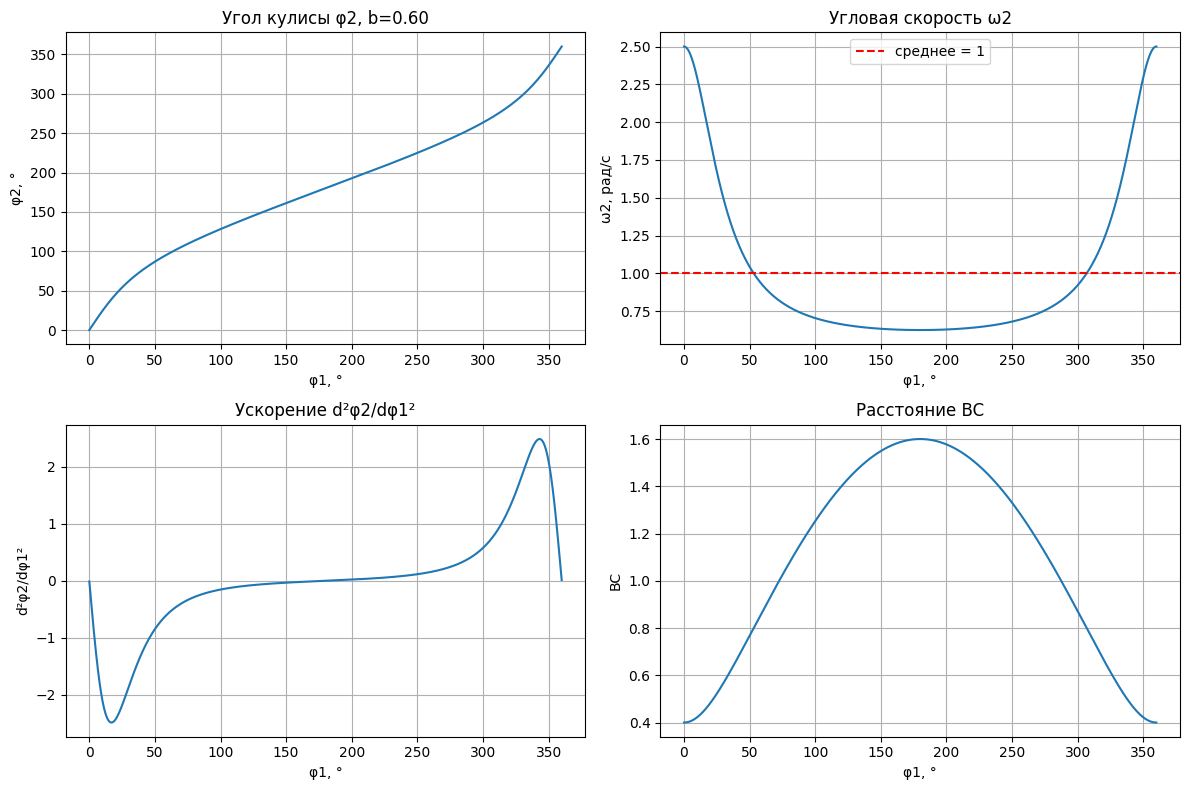

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

AC = 1.0
phi1 = np.linspace(0, 2*np.pi, 3601)
omega1 = 1.0

def compute(b):
    BC = np.sqrt(b**2 + AC**2 - 2*b*AC*np.cos(phi1))
    # Угол кулисы (от линии AB)
    phi2 = np.arctan2(np.sin(phi1), np.cos(phi1) - b)
    phi2 = np.mod(phi2, 2*np.pi)
    # Угловая скорость кулисы
    dphi2_dphi1 = (1 - b*np.cos(phi1)) / BC**2
    omega2 = dphi2_dphi1 * omega1
    # Ускорение (численно)
    d2phi2 = np.gradient(dphi2_dphi1, phi1)
    return phi2, omega2, d2phi2, BC

b_values = np.arange(0.1, 0.99, 0.01)
results = []

for b in b_values:
    phi2, omega2, d2phi2, BC = compute(b)
    omega2_mean = 1.0
    fast_mask = omega2 > omega2_mean
    idx = np.where(fast_mask)[0]
    if len(idx) == 0:
        fast_angle = 0.0
    else:
        splits = np.where(np.diff(idx) > 1)[0] + 1
        segments = np.split(idx, splits)
        if fast_mask[0] and fast_mask[-1] and len(segments) > 1:
            segments[0] = np.concatenate((segments[-1], segments[0]))
            segments = segments[:-1]
        longest = max(segments, key=len)
        fast_angle = len(longest) * (phi1[1] - phi1[0])
    fast_angle_deg = np.degrees(fast_angle)
    max_omega2 = np.max(omega2)
    min_omega2 = np.min(omega2)
    max_acc = np.max(np.abs(d2phi2))
    results.append((b, fast_angle_deg, max_omega2, min_omega2, max_acc))

print("b\tУгол быстрого проворота, °\tω2 max\tω2 min\tmax|d²φ2/dφ1²|")
for r in results:
    print(f"{r[0]:.2f}\t{r[1]:.2f}\t\t\t{r[2]:.3f}\t{r[3]:.3f}\t{r[4]:.3f}")

best = list(filter(lambda x: f'{x[0]:.2f}' == '0.60', results))[0]
print(f"\nОптимальное b = {best[0]:.2f}, угол быстрого проворота = {best[1]:.2f}°")

b_opt = best[0]
phi2, omega2, d2phi2, BC = compute(b_opt)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].plot(np.degrees(phi1), np.degrees(phi2))
axes[0,0].set_title(f'Угол кулисы φ2, b={b_opt:.2f}')
axes[0,0].set_xlabel('φ1, °')
axes[0,0].set_ylabel('φ2, °')
axes[0,0].grid(True)

axes[0,1].plot(np.degrees(phi1), omega2)
axes[0,1].axhline(1.0, color='r', linestyle='--', label='среднее = 1')
axes[0,1].set_title('Угловая скорость ω2')
axes[0,1].set_xlabel('φ1, °')
axes[0,1].set_ylabel('ω2, рад/с')
axes[0,1].legend()
axes[0,1].grid(True)

axes[1,0].plot(np.degrees(phi1), d2phi2)
axes[1,0].set_title('Ускорение d²φ2/dφ1²')
axes[1,0].set_xlabel('φ1, °')
axes[1,0].set_ylabel('d²φ2/dφ1²')
axes[1,0].grid(True)

axes[1,1].plot(np.degrees(phi1), BC)
axes[1,1].set_title('Расстояние BC')
axes[1,1].set_xlabel('φ1, °')
axes[1,1].set_ylabel('BC')
axes[1,1].grid(True)

plt.tight_layout()
plt.show()

In [5]:
import numpy as np
import matplotlib.pyplot as plt

AC = 1.0
omega1 = 1.0
phi1 = np.linspace(0, 2*np.pi, 36001)  # шаг 0.01°

def compute(b):
    BC = np.sqrt(b**2 + AC**2 - 2*b*AC*np.cos(phi1))

    # φ₂ через арксинус с корректировкой четверти
    sin_phi2 = np.sin(phi1) / BC
    cos_phi2 = (b - np.cos(phi1)) / BC
    phi2 = np.arcsin(sin_phi2)
    phi2 = np.where(cos_phi2 < 0, np.pi - phi2, phi2)
    phi2 = np.mod(phi2, 2*np.pi)

    # Угловая скорость
    dphi2_dphi1 = (1 - b*np.cos(phi1)) / BC**2
    omega2 = dphi2_dphi1 * omega1

    return phi2, omega2, BC

def find_fast_zone(omega2, phi1, phi2):
    """Находит самый длинный непрерывный участок, где omega2 > 1."""
    fast_mask = omega2 > 1.0
    idx = np.where(fast_mask)[0]

    if len(idx) == 0:
        return None

    # Разбиваем на непрерывные сегменты
    splits = np.where(np.diff(idx) > 1)[0] + 1
    segments = np.split(idx, splits)

    # Если быстрая зона пересекает 0/2π — склеиваем
    if fast_mask[0] and fast_mask[-1] and len(segments) > 1:
        segments[0] = np.concatenate((segments[-1], segments[0]))
        segments = segments[:-1]

    longest = max(segments, key=len)

    p1_start = phi1[longest[0]]
    p1_end   = phi1[longest[-1]]
    p2_start = phi2[longest[0]]
    p2_end   = phi2[longest[-1]]

    # Нормировка Δφ₂ в [-180°, +180°]
    dphi2 = p2_end - p2_start
    dphi2 = (dphi2 + np.pi) % (2*np.pi) - np.pi

    # Нормировка Δφ₁ тоже (на случай перехода через 0)
    dphi1 = p1_end - p1_start
    dphi1 = (dphi1 + np.pi) % (2*np.pi) - np.pi

    return {
        'phi1_start_deg': np.degrees(p1_start),
        'phi1_end_deg':   np.degrees(p1_end),
        'phi2_start_deg': np.degrees(p2_start),
        'phi2_end_deg':   np.degrees(p2_end),
        'dphi2_deg':      np.degrees(dphi2),
        'dphi1_deg':      np.degrees(dphi1),
        'n_points':       len(longest),
    }

# ===== ПЕРЕБОР =====
b_values = np.arange(0.05, 1.00, 0.01)
results = []

print(f"{'b':>5} {'φ1 нач':>10} {'φ1 кон':>10} {'Δφ1':>8} "
      f"{'φ2 нач':>10} {'φ2 кон':>10} {'Δφ2':>8}")
print("-" * 72)

for b in b_values:
    phi2, omega2, BC = compute(b)
    zone = find_fast_zone(omega2, phi1, phi2)
    if zone is None:
        continue
    zone['b'] = b
    results.append(zone)
    print(f"{b:>5.2f} {zone['phi1_start_deg']:>10.2f} {zone['phi1_end_deg']:>10.2f} "
          f"{zone['dphi1_deg']:>8.2f} {zone['phi2_start_deg']:>10.2f} "
          f"{zone['phi2_end_deg']:>10.2f} {zone['dphi2_deg']:>8.2f}")


    b     φ1 нач     φ1 кон      Δφ1     φ2 нач     φ2 кон      Δφ2
------------------------------------------------------------------------
 0.05     272.87      87.13   174.26     270.00      90.00  -179.99
 0.06     273.44      86.56   173.12     270.00      90.00  -180.00
 0.07     274.02      85.98   171.96     269.99      90.01  -179.99
 0.08     274.59      85.41   170.82     270.00      90.00  -180.00
 0.09     275.17      84.83   169.66     269.99      90.01  -179.99
 0.10     275.74      84.26   168.52     270.00      90.00  -180.00
 0.11     276.32      83.68   167.36     270.00      90.00  -179.99
 0.12     276.90      83.10   166.20     269.99      90.01  -179.98
 0.13     277.47      82.53   165.06     270.00      90.00  -180.00
 0.14     278.05      81.95   163.90     270.00      90.00  -180.00
 0.15     278.63      81.37   162.74     270.00      90.00  -179.99
 0.16     279.21      80.79   161.58     270.00      90.00  -179.99
 0.17     279.79      80.21   160.42     27

/tmp/ipykernel_2987/61032975.py:14: RuntimeWarning: invalid value encountered in arcsin
  phi2 = np.arcsin(sin_phi2)


In [6]:
import numpy as np

AC = 1.0

def phi2_of_phi1(phi1, b):
    BC = np.sqrt(b**2 + AC**2 - 2*b*AC*np.cos(phi1))
    sin_phi2 = np.sin(phi1) / BC
    cos_phi2 = (b - np.cos(phi1)) / BC
    phi2 = np.arcsin(sin_phi2)
    phi2 = np.where(cos_phi2 < 0, np.pi - phi2, phi2)
    phi2 = np.mod(phi2, 2*np.pi)
    return phi2

# 1° grid of crank angle
phi1_deg = np.arange(0, 360, 1)          # 0, 1, 2, ..., 359
phi1_rad = np.radians(phi1_deg)

print(f"{'b':>5} | {'Δφ2 per 1° step (deg)':>30}")
print(f"{'':>5} | {'at φ1=0°':>10} {'at φ1=90°':>10} {'at φ1=180°':>10} {'max':>10} {'min':>10}")
print("-" * 80)

for b in np.arange(0.05, 1.00, 0.05):
    phi2 = phi2_of_phi1(phi1_rad, b)

    # Difference between consecutive steps: this is Δφ2 per 1° of φ1
    dphi2 = np.diff(phi2)
    # Wrap into [-180°, +180°]
    dphi2 = (dphi2 + np.pi) % (2*np.pi) - np.pi
    # Take magnitude — this is "how many degrees did the rocker move in 1° of crank"
    dphi2_deg = np.abs(np.degrees(dphi2))

    # At specific crank angles
    at_0   = dphi2_deg[0]      # step 0° → 1°
    at_90  = dphi2_deg[90]     # step 90° → 91°
    at_180 = dphi2_deg[180]    # step 180° → 181°

    print(f"{b:>5.2f} | {at_0:>10.2f} {at_90:>10.2f} {at_180:>10.2f} "
          f"{dphi2_deg.max():>10.2f} {dphi2_deg.min():>10.2f}")


    b |          Δφ2 per 1° step (deg)
      |   at φ1=0°  at φ1=90° at φ1=180°        max        min
--------------------------------------------------------------------------------
 0.05 |       1.05       1.00       0.95       1.05       0.95
 0.10 |       1.11       0.99       0.91       1.11       0.91
 0.15 |       1.18       0.98       0.87       1.18       0.87
 0.20 |       1.25       0.96       0.83       1.25       0.83
 0.25 |       1.33       0.94       0.80       1.33       0.80
 0.30 |       1.43       0.92       0.77       1.43       0.77
 0.35 |       1.54       0.89       0.74       1.54       0.74
 0.40 |       1.67       0.86       0.71       1.67       0.71
 0.45 |       1.82       0.83       0.69       1.82       0.69
 0.50 |       2.00       0.80       0.67       2.00       0.67
 0.55 |       2.22       0.77       0.65       2.22       0.65
 0.60 |       2.50       0.73       0.63       2.50       0.63
 0.65 |       2.86       0.70       0.61       2.86       0.6

In [7]:
for b in [0.6, 0.87, 0.97]:
    phi2 = phi2_of_phi1(phi1_rad, b)
    dphi2 = np.diff(phi2)
    dphi2 = (dphi2 + np.pi) % (2*np.pi) - np.pi
    dphi2_deg = np.abs(np.degrees(dphi2))

    print(f"\n{'='*60}")
    print(f"b = {b}")
    print(f"{'='*60}")
    print(f"{'φ1 from':>10} {'φ1 to':>8} {'φ2 from':>10} {'φ2 to':>10} {'Δφ2':>10}")
    print("-" * 60)

    for i, v in enumerate(dphi2_deg):
        phi2_from = np.degrees(phi2[i])
        phi2_to   = np.degrees(phi2[i+1])
        print(f"{i:>10} {i+1:>8} {phi2_from:>10.3f} {phi2_to:>10.3f} {v:>10.3f}")


b = 0.6
   φ1 from    φ1 to    φ2 from      φ2 to        Δφ2
------------------------------------------------------------
         0        1    180.000    177.501      2.499
         1        2    177.501    175.006      2.495
         2        3    175.006    172.520      2.486
         3        4    172.520    170.048      2.472
         4        5    170.048    167.594      2.455
         5        6    167.594    165.160      2.433
         6        7    165.160    162.753      2.408
         7        8    162.753    160.373      2.379
         8        9    160.373    158.026      2.348
         9       10    158.026    155.712      2.313
        10       11    155.712    153.436      2.277
        11       12    153.436    151.197      2.238
        12       13    151.197    148.999      2.198
        13       14    148.999    146.843      2.157
        14       15    146.843    144.728      2.114
        15       16    144.728    142.657      2.071
        16       17    142.65

In [ ]:
import numpy as np

AC = 1.0
target_dphi2 = 28.0              # degrees — the entrance zone
half_target = target_dphi2 / 2   # ±14°

phi1_fine = np.linspace(0, 2*np.pi, 360001)   # 0.001° resolution

def phi2_of_phi1(phi1, b):
    BC = np.sqrt(b**2 + 1 - 2*b*np.cos(phi1))
    sin_phi2 = np.sin(phi1) / BC
    cos_phi2 = (b - np.cos(phi1)) / BC
    phi2 = np.arcsin(sin_phi2)
    phi2 = np.where(cos_phi2 < 0, np.pi - phi2, phi2)
    phi2 = np.mod(phi2, 2*np.pi)
    # center around 180° (so that φ1 = 0 gives φ2 = 180°)
    phi2 = np.where(phi2 > np.pi, phi2 - 2*np.pi, phi2)  # → [-π, π]
    return phi2

print(f"{'b':>6} | {'Δφ1 (deg)':>12} | {'φ1_start':>10} {'φ1_end':>10} | "
      f"{'φ2 at start':>12} {'φ2 at end':>12}")
print("-" * 80)

results = []

for b in np.arange(0.05, 1.00, 0.05):
    phi2 = phi2_of_phi1(phi1_fine, b)

    # We want the interval where phi2 goes from +14° to -14° (or the other way)
    # i.e., when |phi2| < 14° near the fast point (φ1 = 0)

    # Actually near φ1 = 0, φ2 = 180° (because of how atan2 evaluates)
    # Let me recenter so φ1=0 gives φ2 = 0
    # Easy fix: subtract 180° from phi2 everywhere

    phi2_centered = phi2 - np.pi   # now φ1=0 → φ2 = 0
    phi2_centered = (phi2_centered + np.pi) % (2*np.pi) - np.pi   # wrap to [-π,π]

    # Find where |phi2_centered| < half_target (14°)
    target_rad = np.radians(half_target)
    mask = np.abs(phi2_centered) < target_rad

    if not mask.any():
        continue

    # Take the contiguous segment that contains φ1 = 0
    idx = np.where(mask)[0]
    # Find segment containing the smallest index (near φ1 = 0)
    segments = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)

    # Pick the segment containing the point closest to φ1 = 0
    central_segment = min(segments, key=lambda s: np.min(np.abs(phi1_fine[s])))

    phi1_start = phi1_fine[central_segment[0]]
    phi1_end   = phi1_fine[central_segment[-1]]
    phi2_start = phi2_centered[central_segment[0]]
    phi2_end   = phi2_centered[central_segment[-1]]

    dphi1 = np.degrees(phi1_end - phi1_start)

    results.append({
        'b': b,
        'dphi1_deg': dphi1,
        'phi1_start_deg': np.degrees(phi1_start),
        'phi1_end_deg':   np.degrees(phi1_end),
        'phi2_start_deg': np.degrees(phi2_start),
        'phi2_end_deg':   np.degrees(phi2_end),
    })

    print(f"{b:>6.2f} | {dphi1:>12.3f} | {np.degrees(phi1_start):>10.3f} "
          f"{np.degrees(phi1_end):>10.3f} | {np.degrees(phi2_start):>12.3f} "
          f"{np.degrees(phi2_end):>12.3f}")

# Find b that minimizes dphi1
best = min(results, key=lambda r: r['dphi1_deg'])
print()
print(f"Best b = {best['b']:.2f}: Δφ1 = {best['dphi1_deg']:.3f}° "
      f"for Δφ2 = {target_dphi2}°")

     b |    Δφ1 (deg) |   φ1_start     φ1_end |  φ2 at start    φ2 at end
--------------------------------------------------------------------------------
  0.05 |       13.306 |      0.000     13.306 |        0.000      -13.999
  0.10 |       12.613 |      0.000     12.613 |        0.000      -13.999
  0.15 |       11.920 |      0.000     11.920 |        0.000      -14.000
  0.20 |       11.226 |      0.000     11.226 |        0.000      -13.999
  0.25 |       10.532 |      0.000     10.532 |        0.000      -13.999
  0.30 |        9.838 |      0.000      9.838 |        0.000      -14.000
  0.35 |        9.142 |      0.000      9.142 |        0.000      -13.999
  0.40 |        8.446 |      0.000      8.446 |        0.000      -13.999
  0.45 |        7.750 |      0.000      7.750 |        0.000      -14.000
  0.50 |        7.052 |      0.000      7.052 |        0.000      -13.999
  0.55 |        6.353 |      0.000      6.353 |        0.000      -13.998
  0.60 |        5.653 |      0.

In [8]:
import numpy as np

AC = 1.0

def phi2_of_phi1(phi1, b):
    BC = np.sqrt(b**2 + 1 - 2*b*np.cos(phi1))
    sin_phi2 = np.sin(phi1) / BC
    cos_phi2 = (b - np.cos(phi1)) / BC
    phi2 = np.arcsin(sin_phi2)
    phi2 = np.where(cos_phi2 < 0, np.pi - phi2, phi2)
    phi2 = np.mod(phi2, 2*np.pi)
    # Center so φ1 = 0 → φ2 = 0 (the fast point)
    phi2 = phi2 - np.pi
    phi2 = (phi2 + np.pi) % (2*np.pi) - np.pi
    return phi2

# 1° step of φ1
phi1_deg = np.arange(0, 361, 1)
phi1_rad = np.radians(phi1_deg)

# Fast-zone threshold: a step is "fast" if Δφ2 > K
K = 2.0     # degrees per 1 degree of φ1 — tune this

print(f"{'b':>5} | {'φ1 range of fast zone':>25} | {'Δφ2 total':>10}")
print("-" * 65)

for b in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.97]:
    phi2 = phi2_of_phi1(phi1_rad, b)
    dphi2 = np.diff(phi2)
    dphi2 = (dphi2 + np.pi) % (2*np.pi) - np.pi
    dphi2_deg = np.abs(np.degrees(dphi2))

    # Find fast steps
    fast = dphi2_deg > K
    idx = np.where(fast)[0]

    if len(idx) == 0:
        print(f"{b:>5.2f} | {'—':>25} | {'—':>10}")
        continue

    # Find the contiguous segment that contains φ1 = 0 (boundary between idx 359 and 0)
    # Handle wrap-around: if fast[0] and fast[-1], merge
    if fast[0] and fast[-1]:
        # The fast zone wraps around
        # Find the last False before the fast zone, and first False after
        gaps = np.where(~fast)[0]
        gap_start = gaps[0]      # first slow index after fast zone
        gap_end = gaps[-1]       # last slow index before fast zone
        # Fast zone = indices [gap_end+1, ..., 359] ∪ [0, ..., gap_start-1]
        phi2_start = np.degrees(phi2[gap_start])  # φ2 at the start (end of fast zone going forward)
        # Actually take φ2 values within fast zone
        fast_indices = np.concatenate([np.arange(gap_end+1, 360), np.arange(0, gap_start)])
        phi2_vals = np.degrees(phi2[np.mod(fast_indices, 360)])
        phi2_sweep = phi2_vals.max() - phi2_vals.min()
        phi1_range_deg = len(fast_indices)   # each step = 1°
        print(f"{b:>5.2f} | {'[wrap: 0-'+str(gap_start)+'] + ['+str(gap_end+1)+'-360]':>25} "
              f"| {phi2_sweep:>10.2f}")
    else:
        # No wrap; find the contiguous segment
        segments = np.split(idx, np.where(np.diff(idx) > 1)[0] + 1)
        # The fast zone nearest φ1 = 0
        seg = min(segments, key=lambda s: np.min(np.abs(phi1_rad[s])))
        # φ2 values in this segment (including the point after each step)
        phi2_vals = np.degrees(phi2[seg[0]:seg[-1]+2])
        phi2_sweep = phi2_vals.max() - phi2_vals.min()
        phi1_range_deg = seg[-1] - seg[0] + 1
        print(f"{b:>5.2f} | [{np.degrees(phi1_rad[seg[0]]):.0f}°, "
              f"{np.degrees(phi1_rad[seg[-1]+1]):.0f}°] "
              f"({phi1_range_deg}°) | {phi2_sweep:>10.2f}")

    b |     φ1 range of fast zone |  Δφ2 total
-----------------------------------------------------------------
 0.30 |                         — |          —
 0.40 |                         — |          —
 0.50 |                         — |          —
 0.60 |  [wrap: 0-17] + [343-360] |      76.71
 0.70 |  [wrap: 0-19] + [341-360] |     103.89
 0.80 |  [wrap: 0-18] + [342-360] |     125.82
 0.90 |  [wrap: 0-14] + [346-360] |     145.50
 0.97 |   [wrap: 0-8] + [352-360] |     161.23
